# Proyecto Final: Análisis de E-Commerce y Logística Olist
## 01. Carga, Exploración Inicial e Integración de Tablas (Merge)

---

### 1. Introducción y Objetivo del Notebook
En este primer cuaderno me centro en la integración de los datos:
1. Carga de las 8 tablas maestras del marketplace de Olist.
2. Exploración de los tipos de datos, claves primarias y claves foráneas.
3. Tratamiento previo de pagos y reseñas (evitar duplicados al hacer merge).
4. Unión progresiva (`merge`) tomando como base los artículos vendidos (`order_items`).
5. Comprobación del dataset unificado resultante y exportación para la fase de limpieza.


In [1]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

RAW_DIR = r"c:\Users\Jose\Desktop\cosas\data\proyecto_final\data\raw"
PROCESSED_DIR = r"c:\Users\Jose\Desktop\cosas\data\proyecto_final\data\processed"
os.makedirs(PROCESSED_DIR, exist_ok=True)

print("Entorno configurado correctamente.")


Entorno configurado correctamente.


### 2. Carga de las Fuentes de Datos en Bruto
Cargamos las 8 tablas maestras de Olist para analizar su volumen individual y su esquema de columnas.


In [2]:
# Carga de tablas
df_orders = pd.read_csv(os.path.join(RAW_DIR, 'olist_orders_dataset.csv'))
df_items = pd.read_csv(os.path.join(RAW_DIR, 'olist_order_items_dataset.csv'))
df_customers = pd.read_csv(os.path.join(RAW_DIR, 'olist_customers_dataset.csv'))
df_products = pd.read_csv(os.path.join(RAW_DIR, 'olist_products_dataset.csv'))
df_translation = pd.read_csv(os.path.join(RAW_DIR, 'product_category_name_translation.csv'))
df_sellers = pd.read_csv(os.path.join(RAW_DIR, 'olist_sellers_dataset.csv'))
df_payments = pd.read_csv(os.path.join(RAW_DIR, 'olist_order_payments_dataset.csv'))
df_reviews = pd.read_csv(os.path.join(RAW_DIR, 'olist_order_reviews_dataset.csv'))

# Resumen de dimensiones
tablas = {
    'orders': df_orders,
    'order_items': df_items,
    'customers': df_customers,
    'products': df_products,
    'sellers': df_sellers,
    'payments': df_payments,
    'reviews': df_reviews,
    'category_translation': df_translation
}

resumen_tablas = pd.DataFrame([
    {'Tabla': name, 'Filas': len(df), 'Columnas': len(df.columns), 'Memoria (MB)': df.memory_usage(deep=True).sum() / (1024**2)}
    for name, df in tablas.items()
])
resumen_tablas


,Tabla,Filas,Columnas,Memoria (MB)
0,orders,99441,8,52.94
1,order_items,112650,7,35.99
2,customers,99441,5,26.59
3,products,32951,9,6.30
4,sellers,3095,4,0.59
5,payments,103886,5,16.23
6,reviews,99224,7,39.12
7,category_translation,73,2,0.01


### 3. Modelo de Entidad-Relación y Estrategia de Unión
La arquitectura de Olist se articula en torno a dos tablas centrales:
- **`olist_orders_dataset`**: Registra cada transacción global (1 pedido = 1 cliente).
- **`olist_order_items_dataset`**: Detalla cada artículo dentro de un pedido (1 pedido = 1 o varios artículos).

**Estrategia de granularidad:**
Para que el análisis sea verdaderamente exhaustivo y permita evaluar rentabilidad de productos, dispersión de vendedores y precios unitarios, fijamos la clave principal de análisis en el nivel **`order_item`** (112.650 registros).

Antes de ejecutar los cruces, debemos resolver las relaciones $1:N$ en **pagos** y **reseñas**:
- Un pedido puede tener múltiples filas en `payments` si el cliente combinó varios métodos de pago (ej. vale descuento + tarjeta de crédito) o pagó en varias cuotas.
- Algunos pedidos tienen más de una reseña si el cliente actualizó su opinión.


In [3]:
# 3.1. Agregación de Pagos a nivel pedido (order_id)
# Identificamos el método de pago principal (el de mayor valor)
idx_max_payment = df_payments.groupby('order_id')['payment_value'].idxmax()
df_payment_top_type = df_payments.loc[idx_max_payment, ['order_id', 'payment_type']].rename(
    columns={'payment_type': 'primary_payment_type'}
)

# Métricas agregadas de pago por pedido
df_payments_agg = df_payments.groupby('order_id').agg(
    total_payment_value=('payment_value', 'sum'),
    max_payment_installments=('payment_installments', 'max'),
    payment_methods_count=('payment_sequential', 'count')
).reset_index().merge(df_payment_top_type, on='order_id', how='left')

print(f"Pagos consolidados a nivel pedido: {df_payments_agg.shape[0]:,} pedidos únicos.")
df_payments_agg.head()


Pagos consolidados a nivel pedido: 99,440 pedidos únicos.


,order_id,total_payment_value,max_payment_installments,payment_methods_count,primary_payment_type
0,00010242fe8c5a6d1ba2dd792cb16214,72.19,2,1,credit_card
1,00018f77f2f0320c557190d7a144bdd3,259.83,3,1,credit_card
2,000229ec398224ef6ca0657da4fc703e,216.87,5,1,credit_card
3,00024acbcdf0a6daa1e931b038114c75,25.78,2,1,credit_card
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04,3,1,credit_card


In [4]:
# 3.2. Deduplicación y Consolidación de Reseñas por Pedido
# Si hay varias reseñas, nos quedamos con la más reciente según fecha de creación
df_reviews_sorted = df_reviews.sort_values(['order_id', 'review_creation_date'], ascending=[True, False])
df_reviews_dedup = df_reviews_sorted.drop_duplicates(subset='order_id', keep='first')[
    ['order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date']
]

print(f"Reseñas consolidadas a nivel pedido: {df_reviews_dedup.shape[0]:,} pedidos con reseña.")
df_reviews_dedup.head()


Reseñas consolidadas a nivel pedido: 98,673 pedidos con reseña.


,order_id,review_score,review_comment_title,review_comment_message,review_creation_date
51963,00010242fe8c5a6d1ba2dd792cb16214,5,NaN,"Perfeito, produto entregue antes do combinado.",2017-09-21 00:00:00
27823,00018f77f2f0320c557190d7a144bdd3,4,NaN,NaN,2017-05-13 00:00:00
4218,000229ec398224ef6ca0657da4fc703e,5,NaN,Chegou antes do prazo previsto e o produto sur...,2018-01-23 00:00:00
38844,00024acbcdf0a6daa1e931b038114c75,4,NaN,NaN,2018-08-15 00:00:00
55676,00042b26cf59d7ce69dfabb4e55b4fd9,5,NaN,Gostei pois veio no prazo determinado .,2017-03-02 00:00:00


### 4. Ejecución del Cruce Maestro (Sequential Merge)
Unimos progresivamente todas las tablas utilizando `LEFT JOIN` partiendo de `order_items` para preservar el 100% de los artículos adquiridos.


In [5]:
# 4.1. Traducción previa de nombres de categoría en la tabla de productos
df_products_en = df_products.merge(df_translation, on='product_category_name', how='left')

# 4.2. Cruce integral
print("Iniciando fusión secuencial...")
df_merged = df_items.merge(df_orders, on='order_id', how='left')
print(f"Tras unir 'orders': {df_merged.shape}")

df_merged = df_merged.merge(df_customers, on='customer_id', how='left')
print(f"Tras unir 'customers': {df_merged.shape}")

df_merged = df_merged.merge(df_products_en, on='product_id', how='left')
print(f"Tras unir 'products': {df_merged.shape}")

df_merged = df_merged.merge(df_sellers, on='seller_id', how='left')
print(f"Tras unir 'sellers': {df_merged.shape}")

df_merged = df_merged.merge(df_payments_agg, on='order_id', how='left')
print(f"Tras unir 'payments_agg': {df_merged.shape}")

df_merged = df_merged.merge(df_reviews_dedup, on='order_id', how='left')
print(f"Tras unir 'reviews_dedup': {df_merged.shape}")

print("\n¡Fusión completada con éxito!")


Iniciando fusión secuencial...
Tras unir 'orders': (112650, 14)
Tras unir 'customers': (112650, 18)


Tras unir 'products': (112650, 27)
Tras unir 'sellers': (112650, 30)
Tras unir 'payments_agg': (112650, 34)


Tras unir 'reviews_dedup': (112650, 38)

¡Fusión completada con éxito!


### 5. Comprobación del Dataset Unificado
Reviso las dimensiones finales y el esquema de columnas resultante tras todos los cruces.


In [6]:
filas_finales, cols_finales = df_merged.shape
print(f"Filas finales del dataset: {filas_finales:,}")
print(f"Columnas finales: {cols_finales:,}")

print("\nListado de columnas generadas:")
for i, col in enumerate(df_merged.columns, 1):
    print(f" {i:2d}. {col:32s} (Tipo: {df_merged[col].dtype})")


Filas finales del dataset: 112,650
Columnas finales: 38

Listado de columnas generadas:
  1. order_id                         (Tipo: object)
  2. order_item_id                    (Tipo: int64)
  3. product_id                       (Tipo: object)
  4. seller_id                        (Tipo: object)
  5. shipping_limit_date              (Tipo: object)
  6. price                            (Tipo: float64)
  7. freight_value                    (Tipo: float64)
  8. customer_id                      (Tipo: object)
  9. order_status                     (Tipo: object)
 10. order_purchase_timestamp         (Tipo: object)
 11. order_approved_at                (Tipo: object)
 12. order_delivered_carrier_date     (Tipo: object)
 13. order_delivered_customer_date    (Tipo: object)
 14. order_estimated_delivery_date    (Tipo: object)
 15. customer_unique_id               (Tipo: object)
 16. customer_zip_code_prefix         (Tipo: int64)
 17. customer_city                    (Tipo: object)
 18. custom

In [7]:
# Porcentaje de nulos por columna tras la unión
nulos_resumen = df_merged.isnull().sum()
pct_nulos = (nulos_resumen / len(df_merged)) * 100
df_nulos = pd.DataFrame({'Total_Nulos': nulos_resumen, 'Pct_Nulos (%)': pct_nulos})
df_nulos = df_nulos[df_nulos['Total_Nulos'] > 0].sort_values(by='Total_Nulos', ascending=False)
df_nulos


,Total_Nulos,Pct_Nulos (%)
review_comment_title,99234,88.09
review_comment_message,65249,57.92
order_delivered_customer_date,2454,2.18
product_category_name_english,1603,1.42
product_category_name,1603,1.42
product_name_lenght,1603,1.42
product_description_lenght,1603,1.42
product_photos_qty,1603,1.42
order_delivered_carrier_date,1194,1.06
review_creation_date,942,0.84


C:\Users\Jose\AppData\Local\Temp\ipykernel_33292\119982232.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=order_status_counts.index, y=order_status_counts.values, palette='Blues_r')


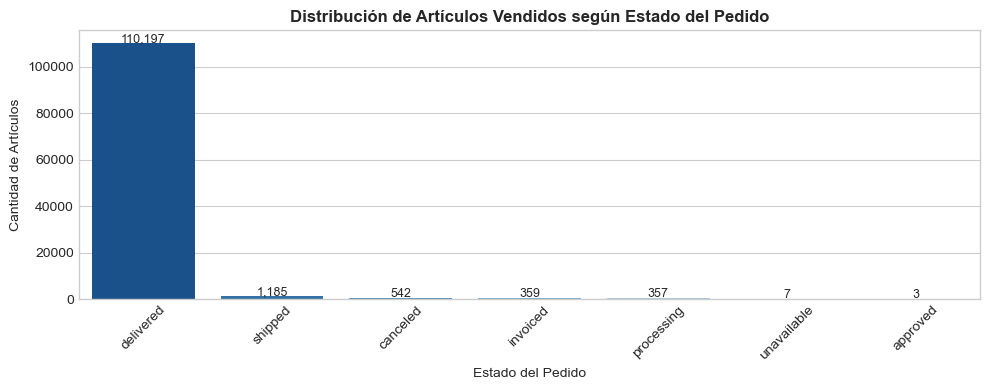

In [8]:
# Visualización del volumen por estado del pedido
plt.figure(figsize=(10, 4))
order_status_counts = df_merged['order_status'].value_counts()
sns.barplot(x=order_status_counts.index, y=order_status_counts.values, palette='Blues_r')
plt.title('Distribución de Artículos Vendidos según Estado del Pedido', fontsize=12, fontweight='bold')
plt.xlabel('Estado del Pedido')
plt.ylabel('Cantidad de Artículos')
plt.xticks(rotation=45)
for i, v in enumerate(order_status_counts.values):
    plt.text(i, v + 500, f"{v:,}", ha='center', fontsize=9)
plt.tight_layout()
plt.show()


### 6. Exportación del Conjunto de Datos Unificado
Guardamos el archivo consolidado `olist_raw_merged.csv` en la carpeta `data/processed/`. Este archivo servirá como entrada para el cuaderno de limpieza profunda y cálculo de KPIs.


In [9]:
output_csv = os.path.join(PROCESSED_DIR, 'olist_raw_merged.csv')
print(f"Guardando dataset consolidado en: {output_csv} ...")
df_merged.to_csv(output_csv, index=False)
size_mb = os.path.getsize(output_csv) / (1024**2)
print(f"¡Guardado completado exitosamente! Tamaño del archivo: {size_mb:.2f} MB")


Guardando dataset consolidado en: c:\Users\Jose\Desktop\cosas\data\proyecto_final\data\processed\olist_raw_merged.csv ...


¡Guardado completado exitosamente! Tamaño del archivo: 53.44 MB


### 7. Resumen de este primer paso
1. **Unión de tablas completada**: Se han integrado las 8 fuentes sin pérdida de registros en `order_items`, con un total de **112.650 filas y 38 columnas**.
2. **Control de duplicados**: La agregación previa de pagos y reseñas evitó multiplicar filas en pedidos con varios métodos de pago.
3. **Puntos para el siguiente cuaderno (limpieza)**:
   - Convertir las columnas de fechas a tipo `datetime`.
   - Imputar nulos en medidas y pesos según la categoría de producto.
   - Crear las variables analíticas de tiempos de entrega, retrasos y envíos interestatales.
